In [15]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict
from dotenv import load_dotenv
import os

### Loading env variables

In [16]:
load_dotenv()
GEMINI_API_KEY=os.getenv('GOOGLE_API_KEY')

### Define LLM

In [17]:
model = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    google_api_key=GEMINI_API_KEY,
    temperature=1.0,  
    max_retries=2,
)

### Define State

In [18]:
class BlogState(TypedDict):

    title: str
    outline: str
    content: str

### Creating Nodes

In [6]:
def create_outline(state: BlogState) -> BlogState:

    # fetch title
    title = state['title']

    # call llm gen outline
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = model.invoke(prompt).content

    # update state
    state['outline'] = outline

    return state

In [7]:
def create_blog(state: BlogState) -> BlogState:

    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the follwing outline \n {outline}'

    content = model.invoke(prompt).content

    state['content'] = content

    return state

### Define and Compile Graph

In [19]:
graph = StateGraph(BlogState)

# nodes
graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)

# edges
graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', END)

workflow = graph.compile()

### Execute the Graph

In [21]:
intial_state = {'title': 'Rise of AI in Morocco'}

final_state = workflow.invoke(intial_state)

print(final_state)

/home/med/miniconda3/envs/langagent/lib/python3.11/site-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/home/med/miniconda3/envs/langagent/lib/python3.11/site-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


{'title': 'Rise of AI in Morocco', 'outline': [{'type': 'text', 'text': 'Here is a detailed, SEO-friendly outline for a blog post titled **"The Rise of AI in Morocco: Bridging Tradition and Technology."**\n\n---\n\n# **Blog Title Options:**\n*   The Rise of AI in Morocco: How the Kingdom is Embracing the Future\n*   From North Africa to the Global Tech Map: The AI Revolution in Morocco\n*   Morocco’s AI Boom: Opportunities, Challenges, and the Road Ahead\n\n---\n\n## **I. Introduction**\n*   **The Hook:** Morocco is widely known for its rich history, bustling medinas, and tourism, but a quiet revolution is taking place beneath the surface—artificial intelligence.\n*   **Current Context:** Mention Morocco’s strategic positioning as a bridge between Europe, Africa, and the Middle East. \n*   **Thesis Statement:** Driven by government vision, a booming startup ecosystem, and a young, tech-savvy population, Morocco is rapidly emerging as an AI hub in North Africa.\n\n---\n\n## **II. The Ca

In [23]:
print(final_state['outline'])

[{'type': 'text', 'text': 'Here is a detailed, SEO-friendly outline for a blog post titled **"The Rise of AI in Morocco: Bridging Tradition and Technology."**\n\n---\n\n# **Blog Title Options:**\n*   The Rise of AI in Morocco: How the Kingdom is Embracing the Future\n*   From North Africa to the Global Tech Map: The AI Revolution in Morocco\n*   Morocco’s AI Boom: Opportunities, Challenges, and the Road Ahead\n\n---\n\n## **I. Introduction**\n*   **The Hook:** Morocco is widely known for its rich history, bustling medinas, and tourism, but a quiet revolution is taking place beneath the surface—artificial intelligence.\n*   **Current Context:** Mention Morocco’s strategic positioning as a bridge between Europe, Africa, and the Middle East. \n*   **Thesis Statement:** Driven by government vision, a booming startup ecosystem, and a young, tech-savvy population, Morocco is rapidly emerging as an AI hub in North Africa.\n\n---\n\n## **II. The Catalyst: Government Vision and National Strateg

In [24]:
print(final_state['content'])

[{'type': 'text', 'text': "# **The Rise of AI in Morocco: Bridging Tradition and Technology**\n\nMorocco is globally celebrated for its vibrant culture, bustling medinas, intricate architecture, and rich history as a crossroads of civilizations. Millions visit each year to experience its timeless charm. Yet, beneath this deeply rooted traditional surface, a quiet, high-speed revolution is taking place. \n\nStrategically positioned at the crossroads of Europe, Africa, and the Middle East, Morocco is rapidly transforming into a prominent North African tech hub. Driven by bold government visions, a burgeoning startup ecosystem, and a remarkably young, tech-savvy population, the Kingdom is embracing artificial intelligence (AI) not just as a passing trend, but as a core pillar of its future economic growth. \n\nHere is a closer look at how Morocco is successfully leveraging AI to bridge its ancient heritage with the demands of the digital future.\n\n---\n\n## **I. The Catalyst: Government 

### Visualize Graph (Optional)

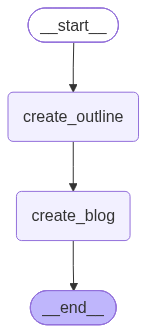

In [25]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())